In [1]:
which_model = 'const'             # 'fun' or 'const'
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
main_pth = '/users/kduecker/hnn-tuning'
import os

pth_mod = os.path.join(main_pth, 'local_hnn/hnn_core/mod')
pth_rslts = os.path.join(main_pth, 'new_cells_dev/optuna/ca_spikes')
os.makedirs(pth_rslts, exist_ok=True)
pth_data = os.path.join(main_pth, 'data/l23')

import pickle

from l23_ca_spikes_optuna import reconstruct_params, get_sections_load_mechs

# neuron imports
import neuron
from neuron import h
from neuron.units import ms, mV

neuron.load_mechanisms(pth_mod)
h.load_file("stdrun.hoc")

import sys
sys.path.append(os.path.join(main_pth, 'new_cells_dev/utils'))
sys.path.append(os.path.join(main_pth, 'new_cells_dev/gen_algo'))
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, linear_gbar

from plot_utils import fig_conductances, fig_compartments
from functools import partial
from scipy.signal import find_peaks
from hnn_core.viz import plot_cell_morphology

import os
import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit

import pickle
import pandas as pd

h.load_file('stdrun.hoc')

from hay_mechs_utils import linear_gbar

plt.rcParams['svg.fonttype'] = 'none'
# Set global font sizes
plt.rcParams['font.size'] = 10          # Default text size
plt.rcParams['axes.titlesize'] = 10      # Title size
plt.rcParams['axes.labelsize'] = 10      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 10    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 10     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 10     # Legend text

from matplotlib import colormaps
cmap = colormaps['viridis']
cols_dist = cmap.colors[0:len(cmap.colors):20]

--No graphics will be displayed.


Text(0.5, 0, 'loss')

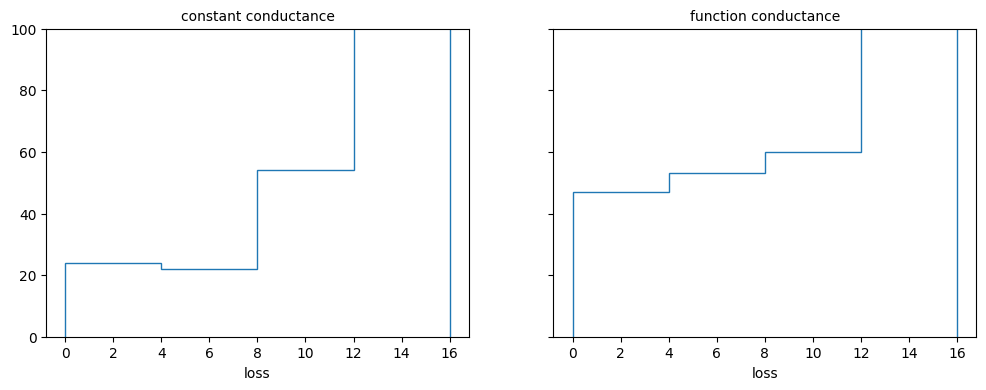

In [2]:
# constant study search

with open(os.path.join(pth_rslts,'study_df_random.pkl'), 'rb') as f:
        study = pickle.load(f)


x = study.value.dropna().values
x = x[x<=16]
u, c = np.histogram(x, bins=4)


# function study search
with open(os.path.join(pth_rslts,'study_df_ca_fun_random.pkl'), 'rb') as f:
        study_ca_fun = pickle.load(f)
x_fun = study_ca_fun.value.dropna().values 
x_fun = x_fun[x_fun<=16]
u_fun, c_fun = np.histogram(x_fun, bins=4)

# loss per study
fig, ax = plt.subplots(1,2, figsize=(12,4), sharex=True, sharey=True)
ax[0].stairs(u, c)
ax[1].stairs(u_fun, c_fun)
ax[1].set_ylim([0, 100])
ax[0].set_title('constant conductance')
ax[1].set_title('function conductance')
ax[0].set_xlabel('loss')
ax[1].set_xlabel('loss')

Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


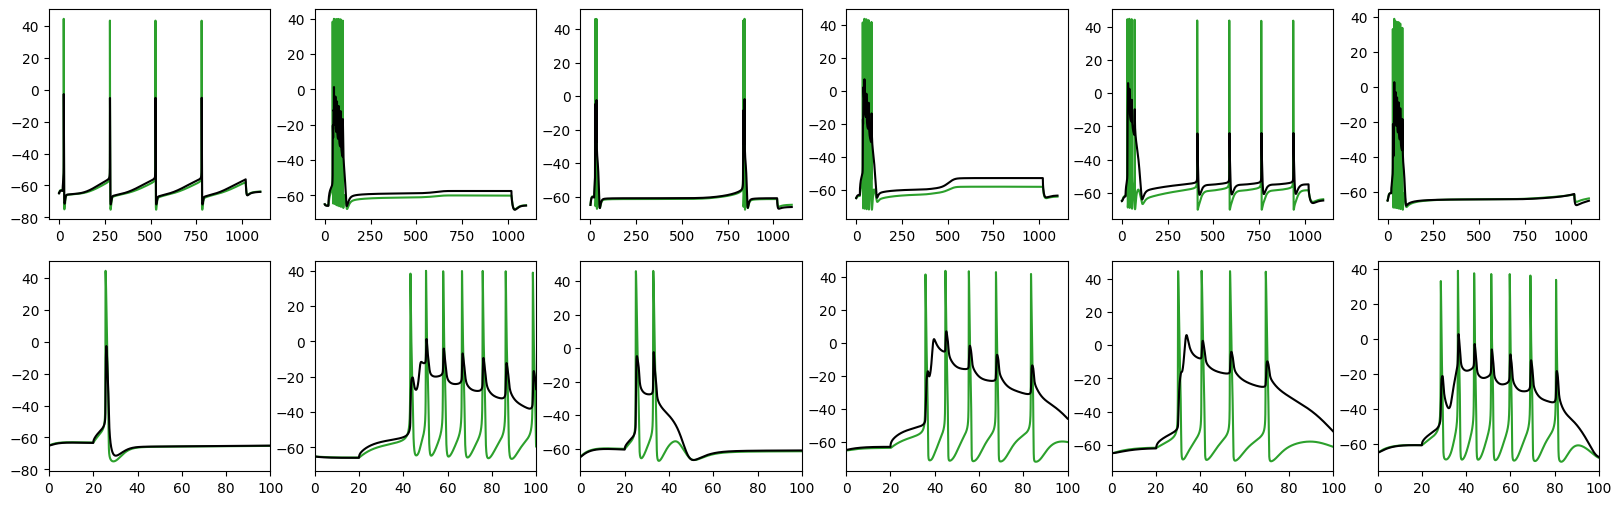

In [3]:
# find the best constant study
best_study = study.loc[study.value == 0]
param_names = ['NaTs2_t_32d_soma','SKv3_1_soma', 'Nap_Et2_soma', 'Ca_HVA_soma', 'Ca_LVAst_soma', 'pas_soma', 'Ih_soma', 'SK_E2_soma', 'Im_soma', 'NaTs2_t_32d_basal', 'SKv3_1_basal', 'Ih_basal', 'pas_basal',
                        'NaTa_t_32d_apical', 'SKv3_1_apical','Ca_HVA_apical', 'Ca_LVAst_apical', 'pas_apical', 'SK_E2_apical', 'Ih_apical', 'Im_apical','decay', 'gamma',
                        'e_pas', 'cm', 'Ra']

fig, ax = plt.subplots(2,6,figsize=(20,6))

for i, study_idx in enumerate(best_study.index):
    optim_vals = []
    for key in param_names:
        optim_vals.append(best_study.loc[study_idx]['params_'+key]) 
    model_params = reconstruct_params(optim_vals, ca_fun_vals=[])

    # Get morphological and conductance parameters
    sections, mech_class, cell_tree = get_sections_load_mechs(model_params)

    # Build cell 
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)

    stim_sect = 'apical_1'
    stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = 0.25

    t = h.Vector().record(h._ref_t)

    stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)
    soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun(1100 * ms)

    t_np = t.as_numpy()
    v_np = stim_v.as_numpy()
    s_np = soma_v.as_numpy()

    ax[0,i].plot(t_np, s_np, color='tab:green')
    ax[0,i].plot(t_np, v_np, color='k')
    ax[1,i].plot(t_np, s_np, color='tab:green')
    ax[1,i].plot(t_np, v_np, color='k')
    ax[1,i].set_xlim(0, 100)

    del l2pyr
    h('forall delete_section()')

best_sol = 0
best_study_c = best_study.loc[best_study.index[0]]

Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms

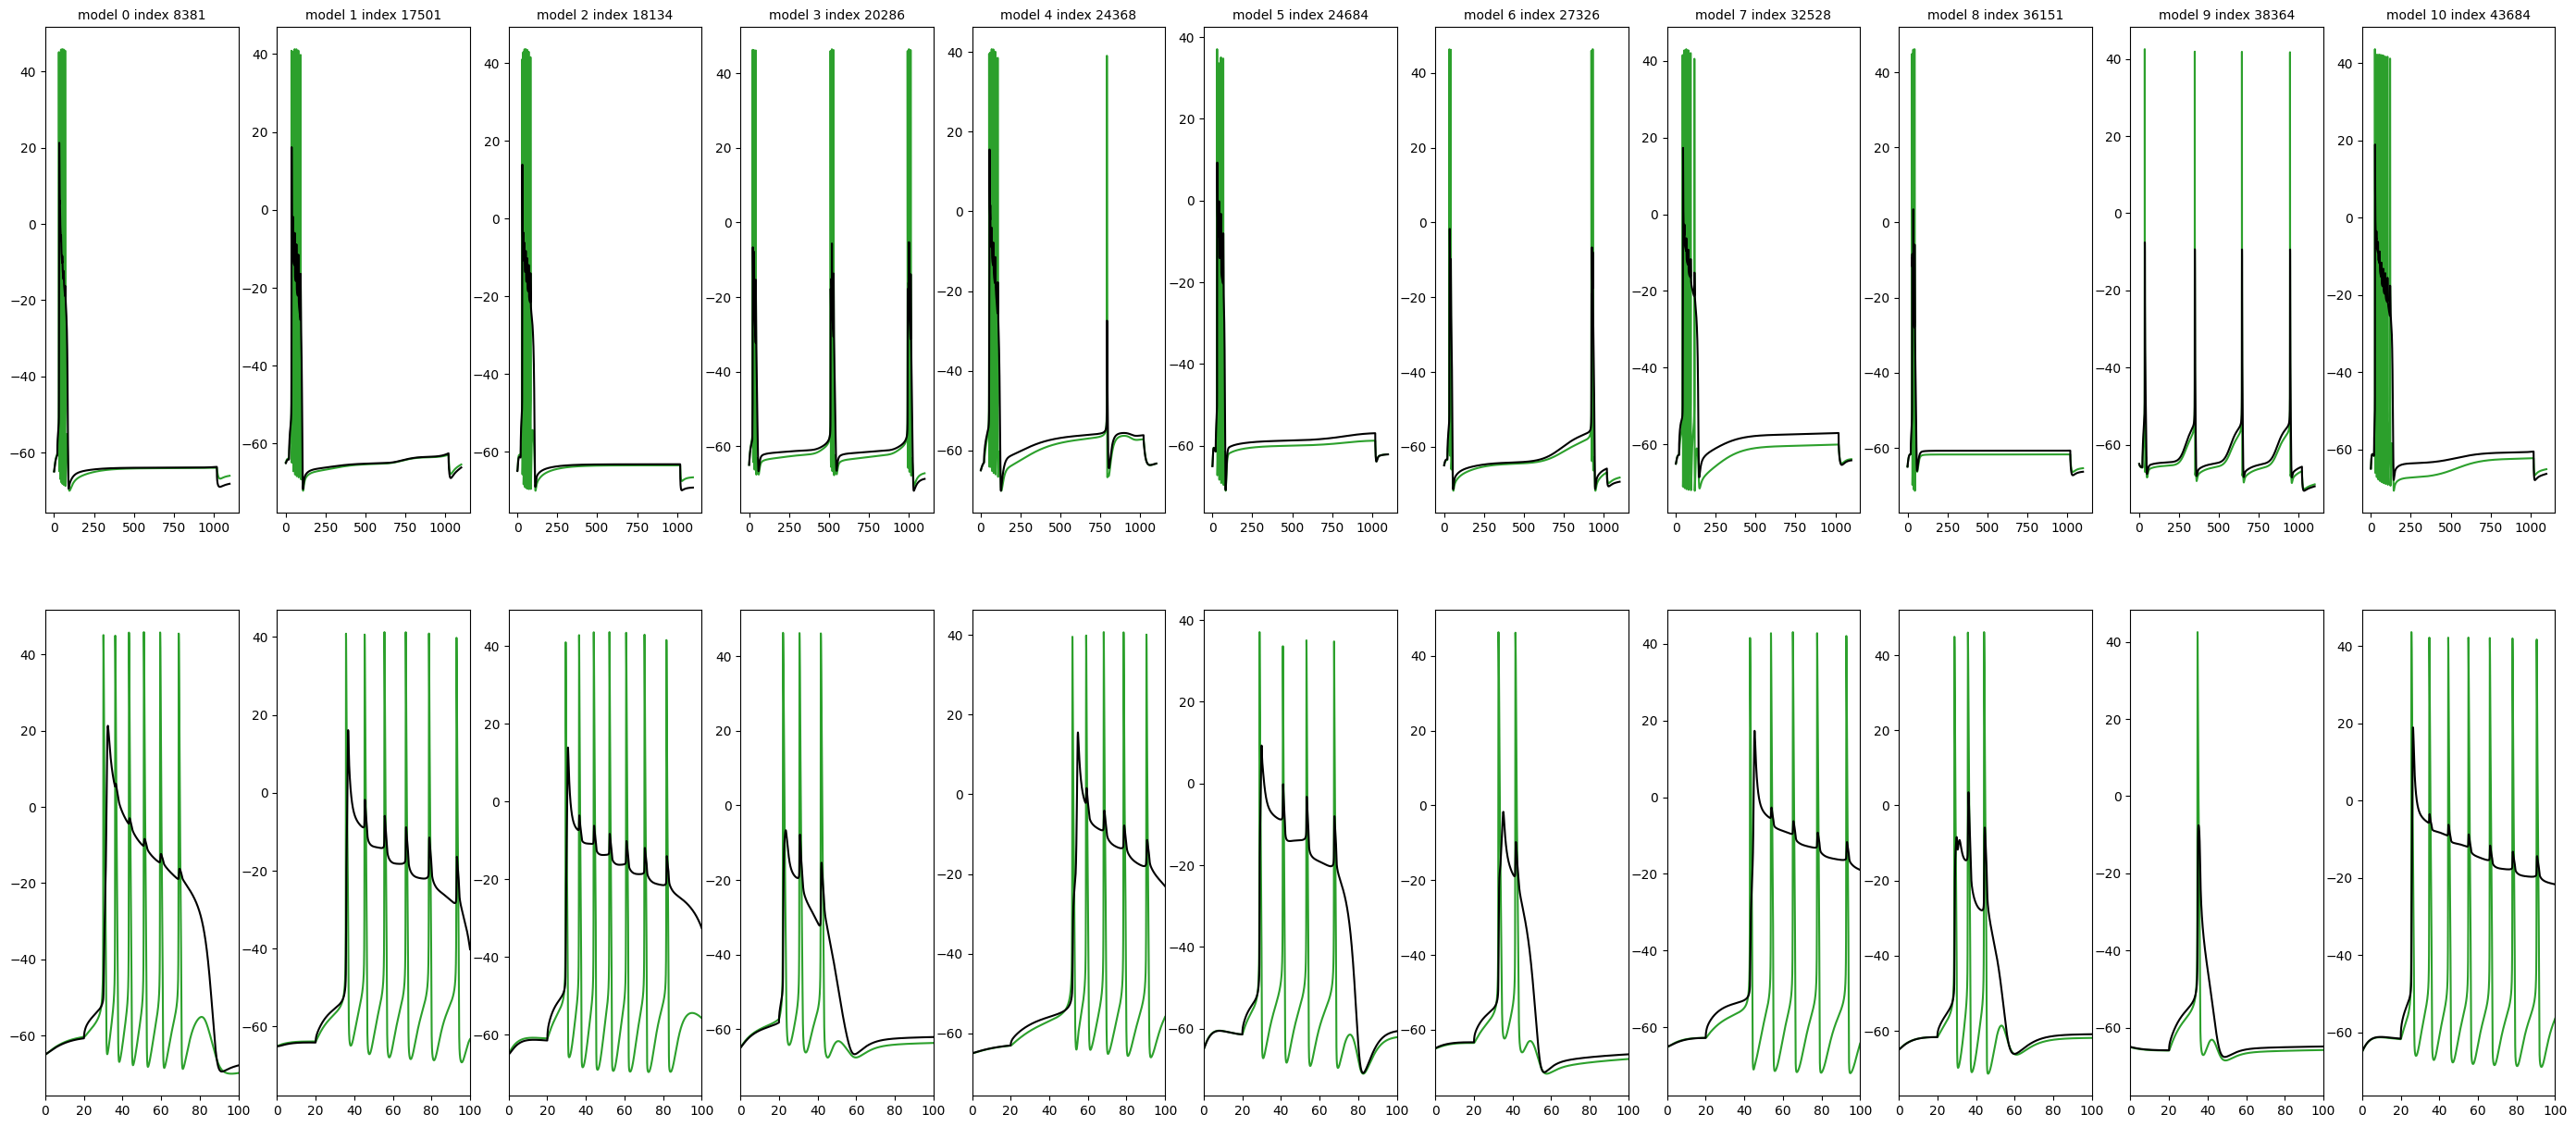

In [4]:
# find the best function study
best_fun_study = study_ca_fun.loc[study_ca_fun.value == 0]

ca_param_names = ['ca_hva_dend', 'ca_hva_xkink', 'ca_hva_hot_low', 'ca_hva_hot_high', 'ca_hva_hot_fact', 'ca_lva_dend', 'ca_lva_xkink', 'ca_lva_hot_low', 'ca_lva_hot_high', 'ca_lva_hot_fact']

fig, ax = plt.subplots(2,11,figsize=(35,15))

for i, study_idx in enumerate(best_fun_study.index):
    optim_vals = []
    for key in param_names:
        optim_vals.append(best_fun_study.loc[study_idx]['params_'+key]) 
    ca_vals = []
    for key in ca_param_names:
            ca_vals.append(best_fun_study.loc[study_idx]['params_'+key])

    model_params = reconstruct_params(optim_vals, ca_fun_vals=ca_vals)

    # Get morphological and conductance parameters
    sections, mech_class, cell_tree = get_sections_load_mechs(model_params)

    # Build cell 
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)

    stim_sect = 'apical_1'
    stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = 0.25

    t = h.Vector().record(h._ref_t)

    stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)
    soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun(1100 * ms)

    t_np = t.as_numpy()
    v_np = stim_v.as_numpy()
    s_np = soma_v.as_numpy()

    ax[0,i].plot(t_np, s_np, color='tab:green')
    ax[0,i].plot(t_np, v_np, color='k')
    ax[0,i].set_title(f'model {i} index {best_fun_study.index[i]}')
    ax[1,i].plot(t_np, s_np, color='tab:green')
    ax[1,i].plot(t_np, v_np, color='k')
    ax[1,i].set_xlim(0, 100)
    del l2pyr
    h('forall delete_section()')

best_study_f = best_fun_study.loc[best_fun_study.index[9]]

In [5]:
# compare to allensdk using best study

if which_model == 'fun':
    best_param = best_study_f
elif which_model == 'const':
    best_param = best_study_c

optim_vals = []
for key in param_names:
    optim_vals.append(best_param['params_'+key]) 
ca_vals = []

if which_model == 'fun':
    for key in ca_param_names:
        ca_vals.append(best_param['params_'+key])

model_params = reconstruct_params(optim_vals, ca_fun_vals=ca_vals)
# Get morphological and conductance parameters
sections, mech_class, cell_tree = get_sections_load_mechs(model_params)


Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


1

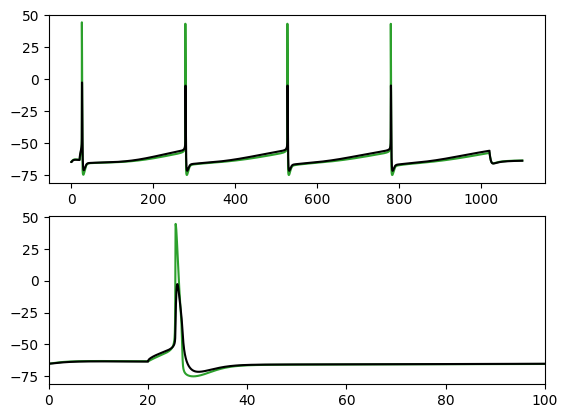

In [6]:
fig, ax = plt.subplots(2,1)
# Build cell 
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim_sect = 'apical_1'
stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = 0.25

t = h.Vector().record(h._ref_t)

stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1100 * ms)

t_np = t.as_numpy()
v_np = stim_v.as_numpy()
s_np = soma_v.as_numpy()

ax[0].plot(t_np, s_np, color='tab:green')
ax[0].plot(t_np, v_np, color='k')
ax[1].plot(t_np, s_np, color='tab:green')
ax[1].plot(t_np, v_np, color='k')
ax[1].set_xlim(0, 100)
del l2pyr
h('forall delete_section()')

In [7]:
with open(os.path.join(pth_data,'ephys_l2.pkl'), 'rb') as f:
    l2_allen = pickle.load(f)

with open(os.path.join(pth_data,'ephys_l3.pkl'), 'rb') as f:
    l3_allen = pickle.load(f)

# l2_allen = pd.read_csv(os.path.join(pth_data, 'ephys_l2.csv'))
# l3_allen = pd.read_csv(os.path.join(pth_data, 'ephys_l3.csv'))

# convert AP width to ms

ephys_measures = dict()

1

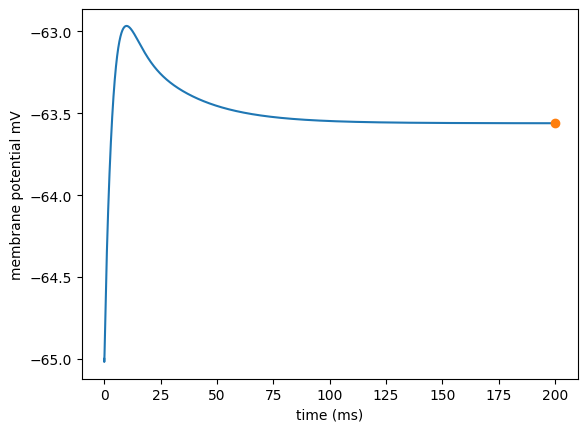

In [8]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = 0.01
h.finitialize()
h.continuerun(200 * ms)

fig, ax = plt.subplots()

# RMP
ephys_measures['RMP'] = soma_v[-3]

ax.plot(t.as_numpy(), soma_v.as_numpy())
ax.set_ylabel('membrane potential mV')
ax.set_xlabel('time (ms)')

ax.plot(t[-3],soma_v[-3], 'o', color='tab:orange')
del l2pyr
h('forall delete_section()')

1

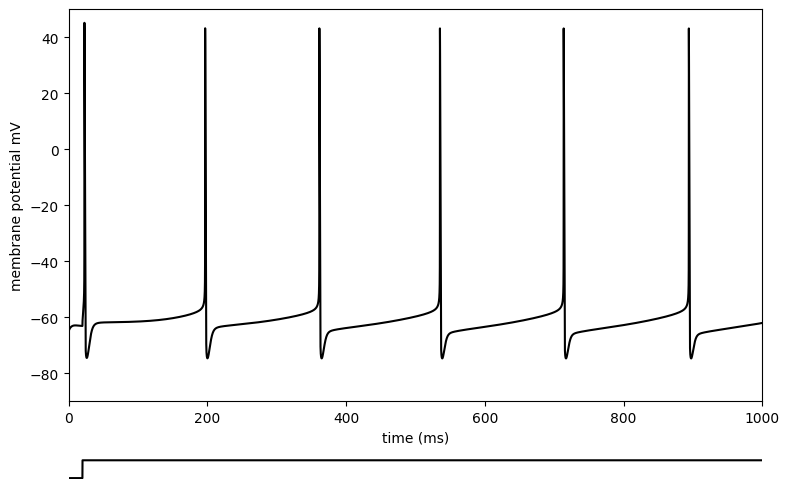

In [9]:
# add stimulation
amp_isi = np.mean(np.concatenate((l2_allen['max_amp_isi'].dropna().values,l3_allen['max_amp_isi'].dropna().values)))

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = amp_isi
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1020 * ms)

fig, ax = plt.subplots(2,1, height_ratios=[1, 0.05],figsize=(8,5))

ax[1].plot(t,clamp_current.as_numpy()*2, color='k')
ax[1].set_axis_off()
ax[0].plot(t,soma_v, color='k')
ax[0].set_xlabel('time (ms)')
ax[0].set_ylabel('membrane potential mV')
ax[0].set_ylim([-90, 50])
ax[0].set_xlim([0, 1000])
ax[1].set_xlim([0, 1000])

fig.tight_layout()
del l2pyr
h('forall delete_section()')

In [10]:
# ISI
from scipy.signal import find_peaks
aps = find_peaks(soma_v,height=0)[0]


ephys_measures['first_isi'] = np.diff(t.as_numpy()[aps])[0]
ephys_measures['mean_isi'] = np.mean(np.diff(t.as_numpy()[aps]))



1

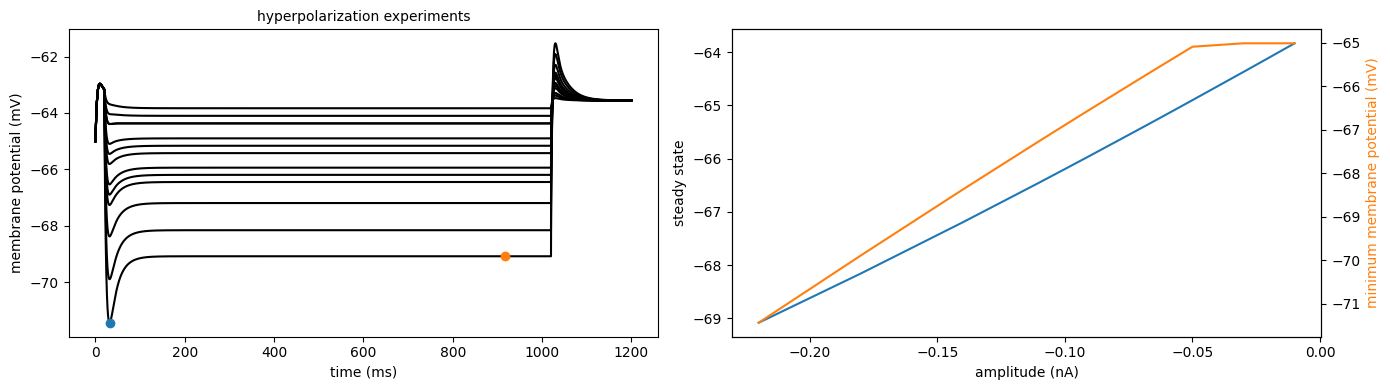

In [11]:
# sag_ratio
from scipy.signal import find_peaks


sag_stim_amp_l2 = l2_allen['sag_stim_amp'].dropna()
sag_stim_amp_l2  = np.concatenate(sag_stim_amp_l2.values)

sag_stim_amp_l3 = l3_allen['sag_stim_amp'].dropna()
sag_stim_amp_l3  = np.concatenate(sag_stim_amp_l3.values)

sag_stim_amp = np.unique(np.concatenate((sag_stim_amp_l2, sag_stim_amp_l3)))

fig, ax = plt.subplots(1,2, figsize = (14, 4))

soma_v = np.zeros((len(sag_stim_amp),int(1/h.dt*1200+1)))
peak_heights = np.zeros_like(sag_stim_amp)
steady_state = np.zeros_like(sag_stim_amp)
min_membr_pot = np.zeros_like(sag_stim_amp)
sag_ratio = np.zeros_like(sag_stim_amp)
for i,amp in enumerate(sag_stim_amp):

    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize()
    h.continuerun(1200 * ms)

    steady_idx = np.argmin(np.abs(t-((stim.delay+stim.dur)*0.9)))
    soma_v[i] = soma_voltg.as_numpy()
    
    min_membr_pot[i] = np.min(soma_v[i])

    steady_state[i] = soma_v[i][steady_idx]

    ax[0].plot(t, soma_voltg, color='k')
    if i == 0:
        ax[0].plot(t[np.argmin(soma_v[i])], min_membr_pot[i], 'o')
        ax[0].plot(t[steady_idx], steady_state[i], 'o')

ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_title('hyperpolarization experiments')
# ax[0].set_ylim([-190, -50])
# ax[0].set_yticks(np.arange(-190, -50, 40))
# ax[0].set_xlim([0, 150])
# ax[0].set_xticks(np.arange(0, 151, 50))
ax[1].plot(sag_stim_amp, steady_state)
ax[1].set_xlabel('amplitude (nA)')
ax[1].set_ylabel('steady state')
ax2 = ax[1].twinx()
ax2.plot(sag_stim_amp, min_membr_pot, color='tab:orange')
ax2.set_ylabel('minimum membrane potential (mV)', color='tab:orange')

fig.tight_layout()

ephys_measures['sag'] = np.mean((min_membr_pot-steady_state)/min_membr_pot)
del l2pyr
h('forall delete_section()')

In [12]:
# Membrane time constant
def exp_func(t, tau, A, C):
    return A * (1 - np.exp(-t / tau)) + C

tau_ms = np.zeros_like(sag_stim_amp)

for i, amp in enumerate(sag_stim_amp):
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)
    h.distance(sec = l2pyr._nrn_sections['soma'])

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 50
    stim.dur = 100
    stim.amp = amp

    v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize()
    h.continuerun(200 * ms)

    v_np = v.as_numpy()
    t_np = t.as_numpy()

    start_idx = np.where(t_np > stim.delay)[0][0]
    end_idx = np.where(t_np > stim.delay + stim.dur*0.9)[0][0]      # steady state, see https://pmc.ncbi.nlm.nih.gov/articles/PMC2775376/

    t_rise = t_np[start_idx:end_idx] - stim.delay # Time starting at 0
    v_rise = v_np[start_idx:end_idx]

    delta_v = np.mean(v_rise) - np.mean(v_np[:start_idx])
    # Fit the exponential function to the data
    popt, pcov = curve_fit(exp_func, t_rise, v_rise, p0=[10, abs(delta_v), v_rise[0]])
    tau_ms[i] = popt[0] # This is the fitted time constant in ms

ephys_measures['tau'] = np.mean(tau_ms)
del l2pyr
h('forall delete_section()')

/tmp/ipykernel_2819754/2769232018.py:3: RuntimeWarning: overflow encountered in exp
  return A * (1 - np.exp(-t / tau)) + C
/tmp/ipykernel_2819754/2769232018.py:3: RuntimeWarning: overflow encountered in multiply
  return A * (1 - np.exp(-t / tau)) + C


1

## AP measures


/tmp/ipykernel_2819754/1449775970.py:74: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  downstroke = np.mean(np.gradient(v_np[int(ap):elbow_p]))


1

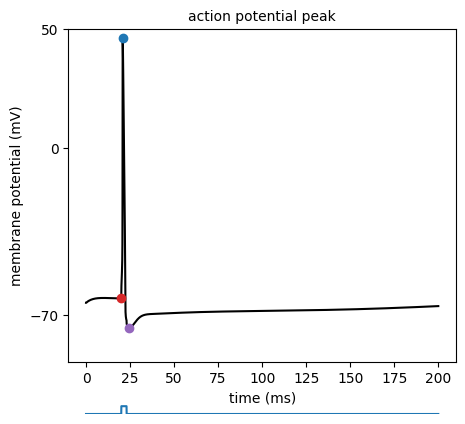

In [13]:
# threshold

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 3
stim.amp = 1.5
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = .01
h.finitialize()
h.continuerun(200 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

v_np = v_soma.as_numpy()
t_np = t.as_numpy()
smooth_v = signal.savgol_filter(np.diff(v_np), 201, 3)

ap_thresh_idx = np.where(smooth_v/np.diff(t_np) > 20)[0][0]+1

ap_thresh = v_np[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

fig, ax = plt.subplots(2,1, figsize=(5,5), height_ratios=[1, 0.05])
ax[0].plot(t, v_soma, color='k')
ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_title('action potential peak')
ax[0].plot(t[np.argmax(v_soma)], ap_peak, 'o', color='tab:blue')
ax[0].set_ylim([-90, 50])
ax[0].set_yticks([-70,0, 50])

ax[0].plot(t[ap_thresh_idx], ap_thresh, 'o', color='tab:red')



# Width at halfmax
# ap_trough = np.argmin(v_np[np.argmax(v_np):])

# half_max = np.min(v_np) + (np.max(v_np)-np.min(v_np))/2
# idx1 = np.argmin(np.abs(v_np[ap_thresh_idx:int(ap)]-half_max))
# idx2 = np.argmin(np.abs(v_np[int(ap):int(ap_trough+np.argmax(v_np))]-half_max))
ap_width = properties['widths'][0]*h.dt
ephys_measures['ap_width'] = ap_width

v2 = np.gradient(np.gradient(v_soma.as_numpy()))

# ax[0].set_xlim([0, 20])
ax[1].plot(t,clamp_current)
ax[0].set_xlabel('time (ms)')
# ax[1].set_xticks(np.arange(0, 25, 5))
# ax[1].set_xlim([0, 20])
ax[1].set_ylabel('current (nA)')
ax[1].set_ylim([0, 3.2])
ax[1].set_axis_off()

start = int(ap[0])
stop = np.argmin(np.abs(t_np-(t_np[ap[0]]+5)))
elbow_p = int(np.argmin(v_np[start:stop]) + start)

upstroke = np.mean(np.gradient(v_np[ap_thresh_idx:int(ap[0])]))
downstroke = np.mean(np.gradient(v_np[int(ap):elbow_p]))

ap_up_down = np.abs(upstroke/downstroke)


ax[0].plot(t.as_numpy()[elbow_p], v_soma.as_numpy()[elbow_p], 'o', color='tab:purple')

ephys_measures['upstroke_downstroke'] = np.abs(upstroke/downstroke)

smooth_v = signal.savgol_filter(np.diff(v_soma.as_numpy()), 101, 3)

ap_thresh_idx = np.where(smooth_v/np.diff(t.as_numpy()) > 20)[0][0]+1
ephys_measures['ap_threshold'] = v_soma[ap_thresh_idx]
del l2pyr
h('forall delete_section()')


1

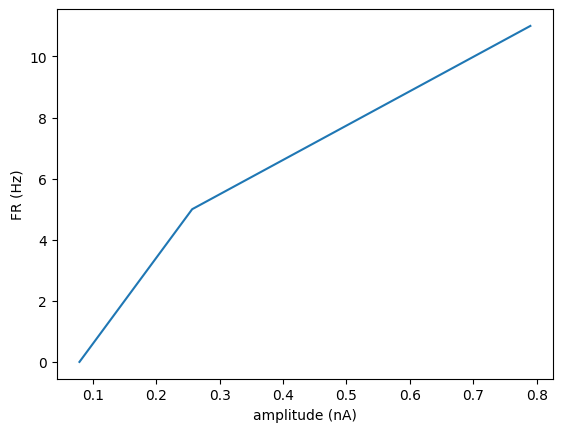

In [14]:
# FR slope
l_stim = 1000

max_amp_isi = np.max(np.concatenate((l2_allen['max_amp_isi'].dropna().values,l3_allen['max_amp_isi'].dropna().values)))
ampl = np.linspace(max_amp_isi/10, max_amp_isi, 5)

soma_v = np.zeros((len(ampl),int(1/h.dt*l_stim+1)))
fr = np.zeros_like(ampl)

for i,amp in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)
    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize()
    h.continuerun((l_stim+stim.delay)* ms)

    pk = find_peaks(v_soma, height=0)

    fr[i] = len(pk[0])


fig, ax = plt.subplots()
ax.plot(ampl,fr)
ax.set_ylabel('FR (Hz)')
ax.set_xlabel('amplitude (nA)')

pA = 0.001 # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.polyfit(ampl,fr,1)[0]
ephys_measures['FR_slope'] *= pA

del l2pyr
h('forall delete_section()')



In [15]:
pA = 0.001 # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.max(np.gradient(fr))#np.polyfit(ampl,fr,1)[0]
ephys_measures['FR_slope'] *= pA

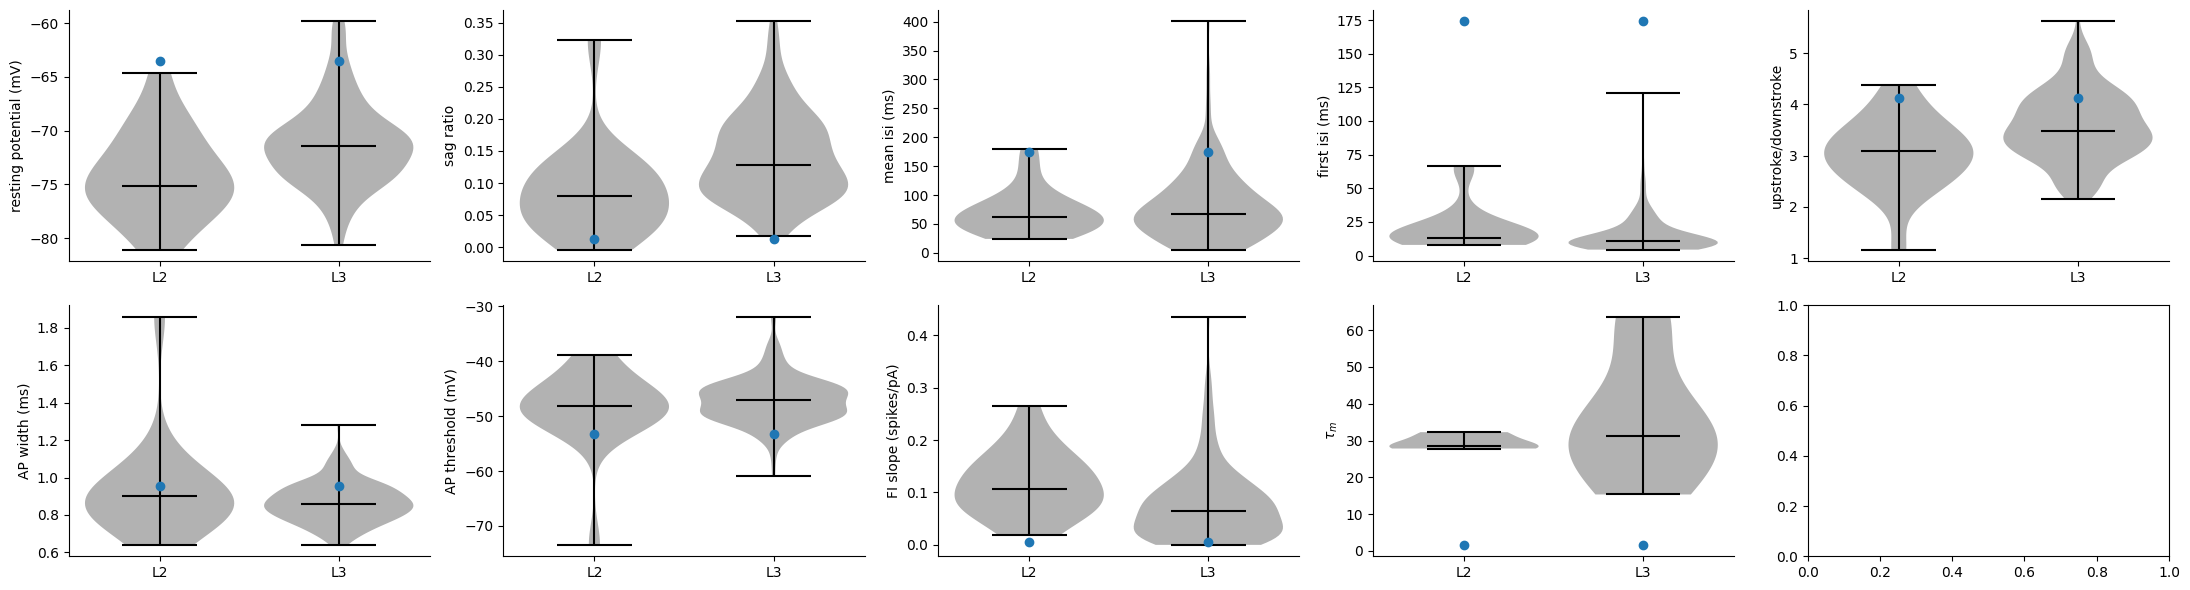

In [16]:
measures = ['RMP', 'sag', 'mean_isi', 'first_isi', 'upstroke_downstroke', 'ap_width', 'ap_threshold', 'FR_slope', 'tau']
label = ['resting potential (mV)', 'sag ratio', 'mean isi (ms)', 'first isi (ms)', 'upstroke/downstroke', 'AP width (ms)', 'AP threshold (mV)', 'FI slope (spikes/pA)', r'$\tau_{m}$']
ylims = [(-85,-50), (-0.1,.4), (0, 450), (0, 450), (1, 6), (0, 2), (-75, -25), (0, 0.5), (0, 65)]
fig, ax = plt.subplots(2,5, figsize=(22,6))

ax = ax.ravel()
for i,m in enumerate(measures):

    data = [l2_allen[m].dropna(),l3_allen[m].dropna()]
    v = ax[i].violinplot(data, positions=[1.2,1.8], vert=True, showmeans=False,
                  showmedians=True)
    # ax[i].set_xticklabels(['L2', 'L3'])

    ax[i].plot(1.2, ephys_measures[m], 'o', color='tab:blue')
    ax[i].plot(1.8, ephys_measures[m], 'o', color='tab:blue')
    ax[i].set_ylabel(label[i])
    ax[i].set_xticks([1.2,1.8],labels=['L2', 'L3'])
    #ax[i].set_ylim(ylims[i])

    # if i in [2,3]:
    #     ax[i].set_yticks(np.linspace(ylims[i][0], ylims[i][1], 4))
    # else:
    #     ax[i].set_yticks(np.linspace(ylims[i][0], ylims[i][1], 3))
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)

    for pc in v['bodies']:
        pc.set_facecolor('black')
    v['cbars'].set_color('black')
    v['cmaxes'].set_color('black')
    v['cmins'].set_color('black')
    v['cmedians'].set_color('black')

fig.tight_layout()


1

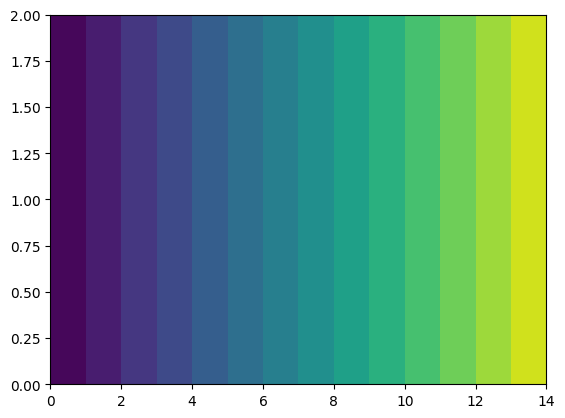

In [17]:
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)


distance = []
h.distance(sec = l2pyr._nrn_sections['soma'])
for section in section_names:
    for seg in l2pyr._nrn_sections[section]:
        distance.append(h.distance(seg.x, sec=seg.sec))

im = plt.pcolormesh(np.tile(np.array(distance),(2,1)), cmap='viridis', vmin=0, vmax=650)

del l2pyr
h('forall delete_section()')

In [18]:
def attenuation_from_section(ref_sect, amp, stim_dur, ax):


    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)
    h.distance(sec = l2pyr._nrn_sections[ref_sect])
    
    
    stim = h.IClamp(l2pyr._nrn_sections[ref_sect](0.5))
    stim.delay = 20
    stim.dur = stim_dur
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    
    ref_voltg = h.Vector().record(l2pyr._nrn_sections[ref_sect](0.5)._ref_v)
    
    sections_minus_ref = [section for section in section_names if section != ref_sect]

    upstroke = []
    dend_voltg = []
    
    distance = []
    
    for s, section in enumerate(sections_minus_ref):
        for sg, seg in enumerate(l2pyr._nrn_sections[section]):

            dend_voltg.append(h.Vector().record(l2pyr._nrn_sections[section](seg.x)._ref_v))

            distance.append(h.distance(seg))

    h.celsius = 37
    h.finitialize()
    h.continuerun(1100 * ms)

    ax.plot(t, ref_voltg, color='k')
    
    t_np = t.as_numpy()
    amp_ref = []
    amp_dend = []
    i = 0
    for s, section in enumerate(sections_minus_ref):
        for sg, seg in enumerate(l2pyr._nrn_sections[section]):
            # low-pass filter 5KHz like in Gidon et al.,
            sfreq = 1000/np.diff(t.as_numpy())[0]
            b, a = signal.butter(0, 5000, btype='low', analog=False, fs=sfreq)

            v = dend_voltg[i].as_numpy()
            d_filt = signal.lfilter(b, a, v)
            r_filt = signal.lfilter(b, a, ref_voltg.as_numpy())

            if amp > 0:  
                # upstroke per ms (Gidon et al., 2020 Fig S5 A)
                upstroke.append(np.max(np.diff(d_filt))/np.diff(t_np)[0])     

                amp_ref.append(np.max(r_filt) - np.min(r_filt))
                amp_dend.append(np.max(d_filt) - np.min(d_filt))

            elif amp     < 0:
                start_idx = np.argmin(np.abs(t_np - (stim.delay+800))) # Gidon 2020
                end_idx = np.argmin(np.abs(t_np - (stim.delay+1000))) # Gooch, 2022

                amp_ref.append(np.mean(r_filt[start_idx:end_idx]))
                amp_dend.append(np.mean(d_filt[start_idx:end_idx]))

            
            ax.plot(t_np,v, color=cols_dist[i])
            i += 1
    
    cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    # calculate attenuation
    atten = np.array(amp_dend) / np.array(amp_ref) * 100

    del l2pyr
    h('forall delete_section()')

    return atten, distance, upstroke

In [19]:
def exp_decay(x, lambda_val, A):
    return A * np.exp(-x / lambda_val)

/tmp/ipykernel_2819754/2243805238.py:71: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x300 with 6 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
/tmp/ipykernel_2819754/2243805238.py:71: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x300 with 7 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)


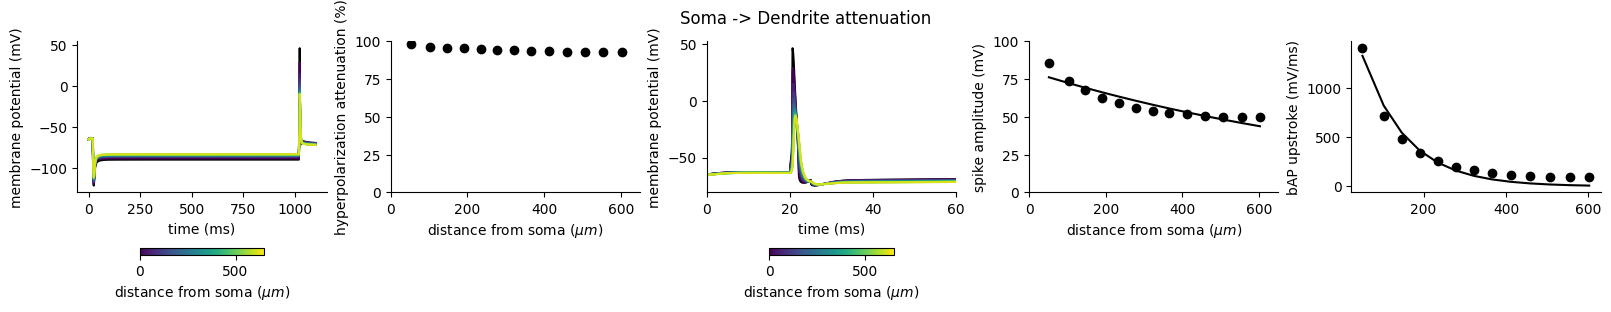

In [20]:
fig, ax = plt.subplots(1,5, figsize=(16,3), constrained_layout=True)

# soma to dendrite attenuation
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
ref_sect = 'soma'

# hyperpolarization attenuation
hyperpol_atten, elec_sep, _ = attenuation_from_section(ref_sect, amp=-2, stim_dur=1000, ax=ax[0])
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(hyperpol_atten), p0=[100, hyperpol_atten[0] ])
lambda_hyperpol = popt[0]

# ax[0].set_ylim([-150, -40])
# ax[0].set_yticks([-150, -100, -50])
ax[1].plot(elec_sep, hyperpol_atten, 'o', color='k')
ax[1].set_xlabel('distance from soma ($\mu m$)')
ax[1].set_ylabel('hyperpolarization attenuation (%)')
#ax[1].set_ylim([0, 100])
ax[1].set_yticks(np.arange(0, 101, 25))

ax[1].set_xlim([0, 650])

# spike attenuation
spike_amp, _, upstroke = attenuation_from_section(ref_sect, amp=2, stim_dur=5,ax=ax[2])

ax[3].plot(elec_sep, spike_amp, 'o', color='k')
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_amp), p0=[100, spike_amp[0] ])
lambda_spike_amp = popt[0]
ax[3].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')

ax[3].set_xlabel('distance from soma ($\mu m$)')
ax[3].set_ylabel('spike amplitude (mV)')
#ax[3].set_ylim([0, 100])
ax[3].set_xlim([0, 650])

# ax[2].set_ylim([-70, 40])
# ax[2].set_yticks([-70, 0, 40])
ax[2].set_xlim([0, 60])
ax[3].set_yticks(np.arange(0, 101, 25))


ax[4].plot(elec_sep, upstroke, 'o', color='k')
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(upstroke), p0=[100, upstroke[0] ])
ax[4].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
lambda_upstroke = popt[0]
#ax[4].set_ylim([0, 250])
ax[4].set_ylabel('bAP upstroke (mV/ms)')

fig.suptitle('Soma -> Dendrite attenuation')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

(20.0, 40.0)

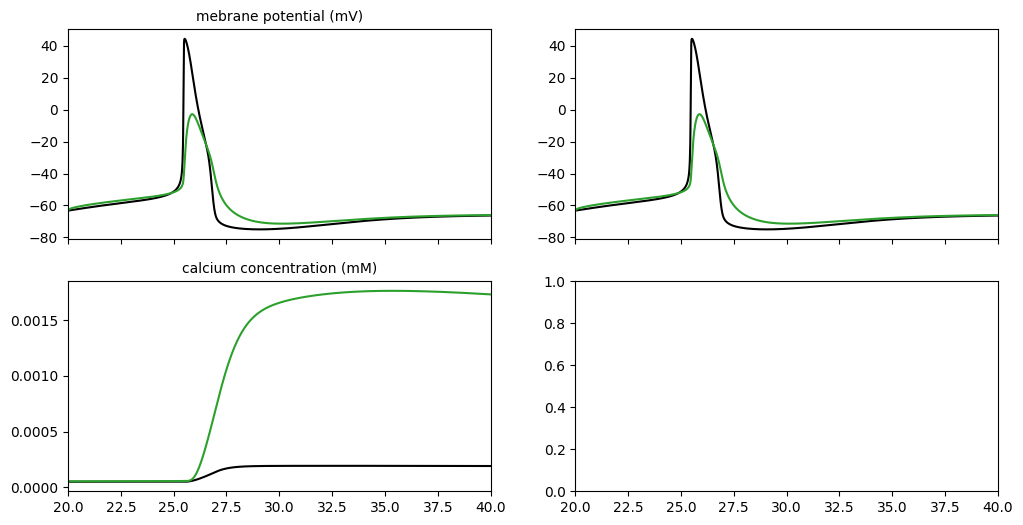

In [38]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)


stim = h.IClamp(l2pyr._nrn_sections['apical_1'](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = .25

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
        
dend_voltg = h.Vector().record(l2pyr._nrn_sections['apical_1'](0.5)._ref_v)

soma_ca = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_cai)
        
dend_ca = h.Vector().record(l2pyr._nrn_sections['apical_1'](0.5)._ref_cai)

h.celsius = 37
h.finitialize()
h.continuerun(1000 * ms)

fig, ax = plt.subplots(2,2, figsize=(12,6), sharex=True)
ax[0,0].plot(t, soma_voltg, color='k')
ax[0,0].plot(t, dend_voltg, color='tab:green')
ax[0,0].set_title('mebrane potential (mV)')
#ax[0].set_xlim([100, 400])#ax[0].set_xlim([100, 400])
ax[1,0].plot(t, soma_ca, color='k')
ax[1,0].plot(t, dend_ca, color='tab:green')
ax[1,0].set_title('calcium concentration (mM)')

ax[0,1].plot(t, soma_voltg, color='k')
ax[0,1].plot(t, dend_voltg, color='tab:green')
ax[0,1].set_xlim([20, 40])

In [41]:
pk_soma = find_peaks(soma_voltg.as_numpy(), height=0)
pk_dend = find_peaks(dend_voltg.as_numpy(), height=-10, width=0.1)